In [31]:
import re
import matplotlib.pyplot as plt
import numpy as np
import os
from scipy.integrate import simps

In [4]:
main_dir = r'M:\90_projects\93_data\P20240653'

In [154]:
def parse_srim_data(data):
    """
    Parse SRIM output data and extract:
    - energy (MeV)
    - electronic stopping power (MeV/mm)
    - nuclear stopping power (MeV/mm) 
    - projected range (μm)
    """
    energy = []
    electronic = []
    nuclear = []
    projected_range = []
    
    # Regular expression pattern to match data lines
    pattern = r'\s*([\d.]+)\s*(?:keV|MeV)\s*([\d.E+-]+)\s*([\d.E+-]+)\s*([\d.]+)\s*(A|um)'
    
    for line in data.split('\n'):
        match = re.match(pattern, line)
        if match:
            # Extract and convert energy to MeV
            energy_val = float(match.group(1))
            unit = 'keV' if 'keV' in line else 'MeV'
            if unit == 'keV':
                energy_val /= 1000  # Convert keV to MeV
            energy.append(energy_val)
            
            # Extract stopping powers (already in MeV/mm)
            electronic.append(float(match.group(2)))
            nuclear.append(float(match.group(3)))
            
            # Extract and convert projected range
            range_val = float(match.group(4))
            range_unit = match.group(5)
            if range_unit == 'A':  # Convert Angstroms to microns
                range_val /= 10000
            elif range_unit == 'um':  # Leave microns as-is
                pass
            projected_range.append(range_val)
    projected_range = np.max(projected_range) - projected_range
    
    return (np.array(energy), 
            np.array(electronic), 
            np.array(nuclear), 
            np.array(projected_range))

In [155]:
fname_H3_Cu = 'Tritium in Copper.txt' 
src_dir_H3_Cu = os.path.join(main_dir, fname_H3_Cu)

In [156]:
# Read data from file
with open(src_dir_H3_Cu, 'r') as f:
    H3_Cu_data = f.read()
# Parse the data
energy_MeV_H3_Cu, electronic_H3_Cu, nuclear_H3_Cu, projected_range_H3_Cu = parse_srim_data(H3_Cu_data)

# Convert stopping power unit to MeV/um
electronic_H3_Cu = electronic_H3_Cu / 1000
nuclear_H3_Cu = nuclear_H3_Cu / 1000

In [157]:
fname_H3_Li6 = 'Tritium in Lithium-6.txt' 
src_dir_H3_Li6 = os.path.join(main_dir, fname_H3_Li6)

In [158]:
# Read data from file
with open(src_dir_H3_Li6, 'r') as f:
    H3_Li6_data = f.read()
# Parse the data
energy_MeV_H3_Li6, electronic_H3_Li6, nuclear_H3_Li6, projected_range_H3_Li6 = parse_srim_data(H3_Li6_data)

# Convert stopping power unit to MeV/um
electronic_H3_Li6 = electronic_H3_Li6 / 1000
nuclear_H3_Li6 = nuclear_H3_Li6 / 1000

In [159]:
fname_alpha_Cu = 'Alpha in Copper.txt' 
src_dir_alpha_Cu = os.path.join(main_dir, fname_alpha_Cu)

In [160]:
# Read data from file
with open(src_dir_alpha_Cu, 'r') as f:
    alpha_Cu_data = f.read()
# Parse the data
energy_MeV_alpha_Cu, electronic_alpha_Cu, nuclear_alpha_Cu, projected_range_alpha_Cu = parse_srim_data(alpha_Cu_data)

# Convert stopping power unit to MeV/um
electronic_alpha_Cu = electronic_alpha_Cu / 1000
nuclear_alpha_Cu = nuclear_alpha_Cu / 1000

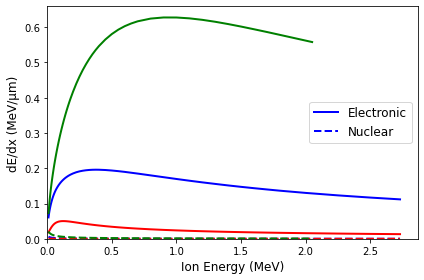

In [168]:
# Create the plot
plt.figure(figsize=(6, 4))

# Plot both stopping powers in blue
plt.plot(energy_MeV_H3_Cu, electronic_H3_Cu, color='blue', linestyle='-', linewidth=2, label='Electronic')
plt.plot(energy_MeV_H3_Cu, nuclear_H3_Cu, color='blue', linestyle='--', linewidth=2, label='Nuclear')

plt.plot(energy_MeV_H3_Li6, electronic_H3_Li6, color='red', linestyle='-', linewidth=2)
plt.plot(energy_MeV_H3_Li6, nuclear_H3_Li6, color='red', linestyle='--', linewidth=2)

plt.plot(energy_MeV_alpha_Cu, electronic_alpha_Cu, color='green', linestyle='-', linewidth=2)
plt.plot(energy_MeV_alpha_Cu, nuclear_alpha_Cu, color='green', linestyle='--', linewidth=2)

# Set axis limits to start at 0
plt.xlim(left=0)
plt.ylim(bottom=0)

# Add labels and title
plt.xlabel('Ion Energy (MeV)', fontsize=12)
plt.ylabel('dE/dx (MeV/μm)', fontsize=12)  # Updated unit
plt.legend(fontsize=12)

# Set y-axis ticks
# plt.yticks([0.05, 0.10, 0.15, 0.20])

# Add grid
# plt.grid(True, ls="-", alpha=0.3)

# Show the plot
plt.tight_layout()
plt.show()

In [162]:
def calculate_range_mev(energy_mev, electronic, nuclear):
    """
    Calculate ion range using scipy.integrate.simps with MeV inputs.
    
    Args:
        energy_mev (np.array): Ion energies in MeV (must be increasing)
        electronic (np.array): Electronic stopping power (MeV/mm)
        nuclear (np.array): Nuclear stopping power (MeV/mm)
    
    Returns:
        np.array: Range in microns
    """
    # Ensure energy is sorted in increasing order
    sort_idx = np.argsort(energy_mev)
    E = energy_mev[sort_idx]
    dE_dx = electronic[sort_idx] + nuclear[sort_idx]
    
    # Prepend zero energy point for proper integration from E=0
    E = np.insert(E, 0, 0)
    dE_dx = np.insert(dE_dx, 0, dE_dx[0])
    
    # Compute range = ∫(dE/(dE/dx)) from 0 to E
    ranges = np.zeros_like(E)
    for i in range(1, len(E)):
        ranges[i] = simps(1/dE_dx[:i+1], E[:i+1])
    
    return ranges[1:]  # Return in microns

In [163]:
# Calculate ranges
# calculated_ranges_H3_Cu = calculate_range_mev(energy_MeV_H3_Cu, electronic_H3_Cu, nuclear_H3_Cu)

# calculated_ranges_H3_Li6 = calculate_range_mev(energy_MeV_H3_Li6, electronic_H3_Li6, nuclear_H3_Li6)
# calculated_ranges_alpha_Cu = calculate_range_mev(energy_MeV_alpha_Cu, electronic_alpha_Cu, nuclear_alpha_Cu)

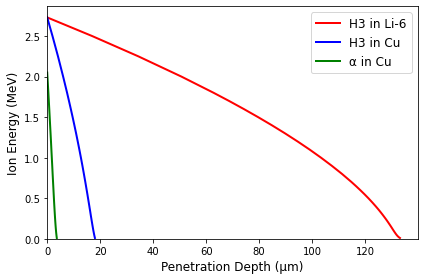

In [174]:
# Plot results with swapped axes
plt.figure(figsize=(6, 4))
plt.plot(projected_range_H3_Li6, energy_MeV_H3_Li6, color='red', lw=2, label='Tritons in Li-6')
plt.plot(projected_range_H3_Cu, energy_MeV_H3_Cu, color='blue', lw=2, label='Tritons in Cu')
plt.plot(projected_range_alpha_Cu, energy_MeV_alpha_Cu, color='green', lw=2, label='Alpha in Cu')

# Update axis labels (now swapped)
plt.xlabel('Penetration Depth (μm)', fontsize=12)
plt.ylabel('Ion Energy (MeV)', fontsize=12)

# Set axis limits to start at 0
plt.xlim(left=0)
plt.ylim(bottom=0)

plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

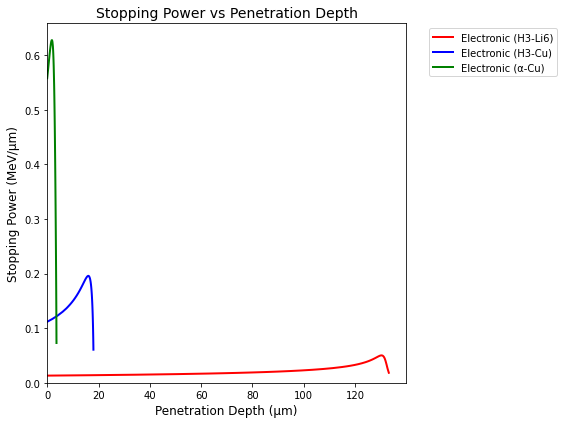

In [175]:
# Create the combined plot
plt.figure(figsize=(8, 6))

# Plot for Tritons in Li-6
plt.plot(projected_range_H3_Li6, electronic_H3_Li6, 'r-', lw=2, label='Electronic (H3-Li6)')


# Plot for Tritons in Cu
plt.plot(projected_range_H3_Cu, electronic_H3_Cu, 'b-', lw=2, label='Electronic (H3-Cu)')


# Plot for Alpha in Cu
plt.plot(projected_range_alpha_Cu, electronic_alpha_Cu, 'g-', lw=2, label='Electronic (α-Cu)')


# Set axis labels and title
plt.xlabel('Penetration Depth (μm)', fontsize=12)
plt.ylabel('Stopping Power (MeV/μm)', fontsize=12)
plt.title('Stopping Power vs Penetration Depth', fontsize=14)

# Configure axes
plt.xlim(left=0)
plt.ylim(bottom=0)

# Add legend and grid
plt.legend(fontsize=10, bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout
plt.tight_layout()
plt.show()